# Truncated-Halo Mass Kernel

This example evaluates Chalcedon's analytic dimensionless enclosed-mass ratio for positive cutoff-to-scale-radius values. The curve uses the truncated profile implemented by `retr_mcutfrommscl`; it is a model calculation rather than an observed halo mass.

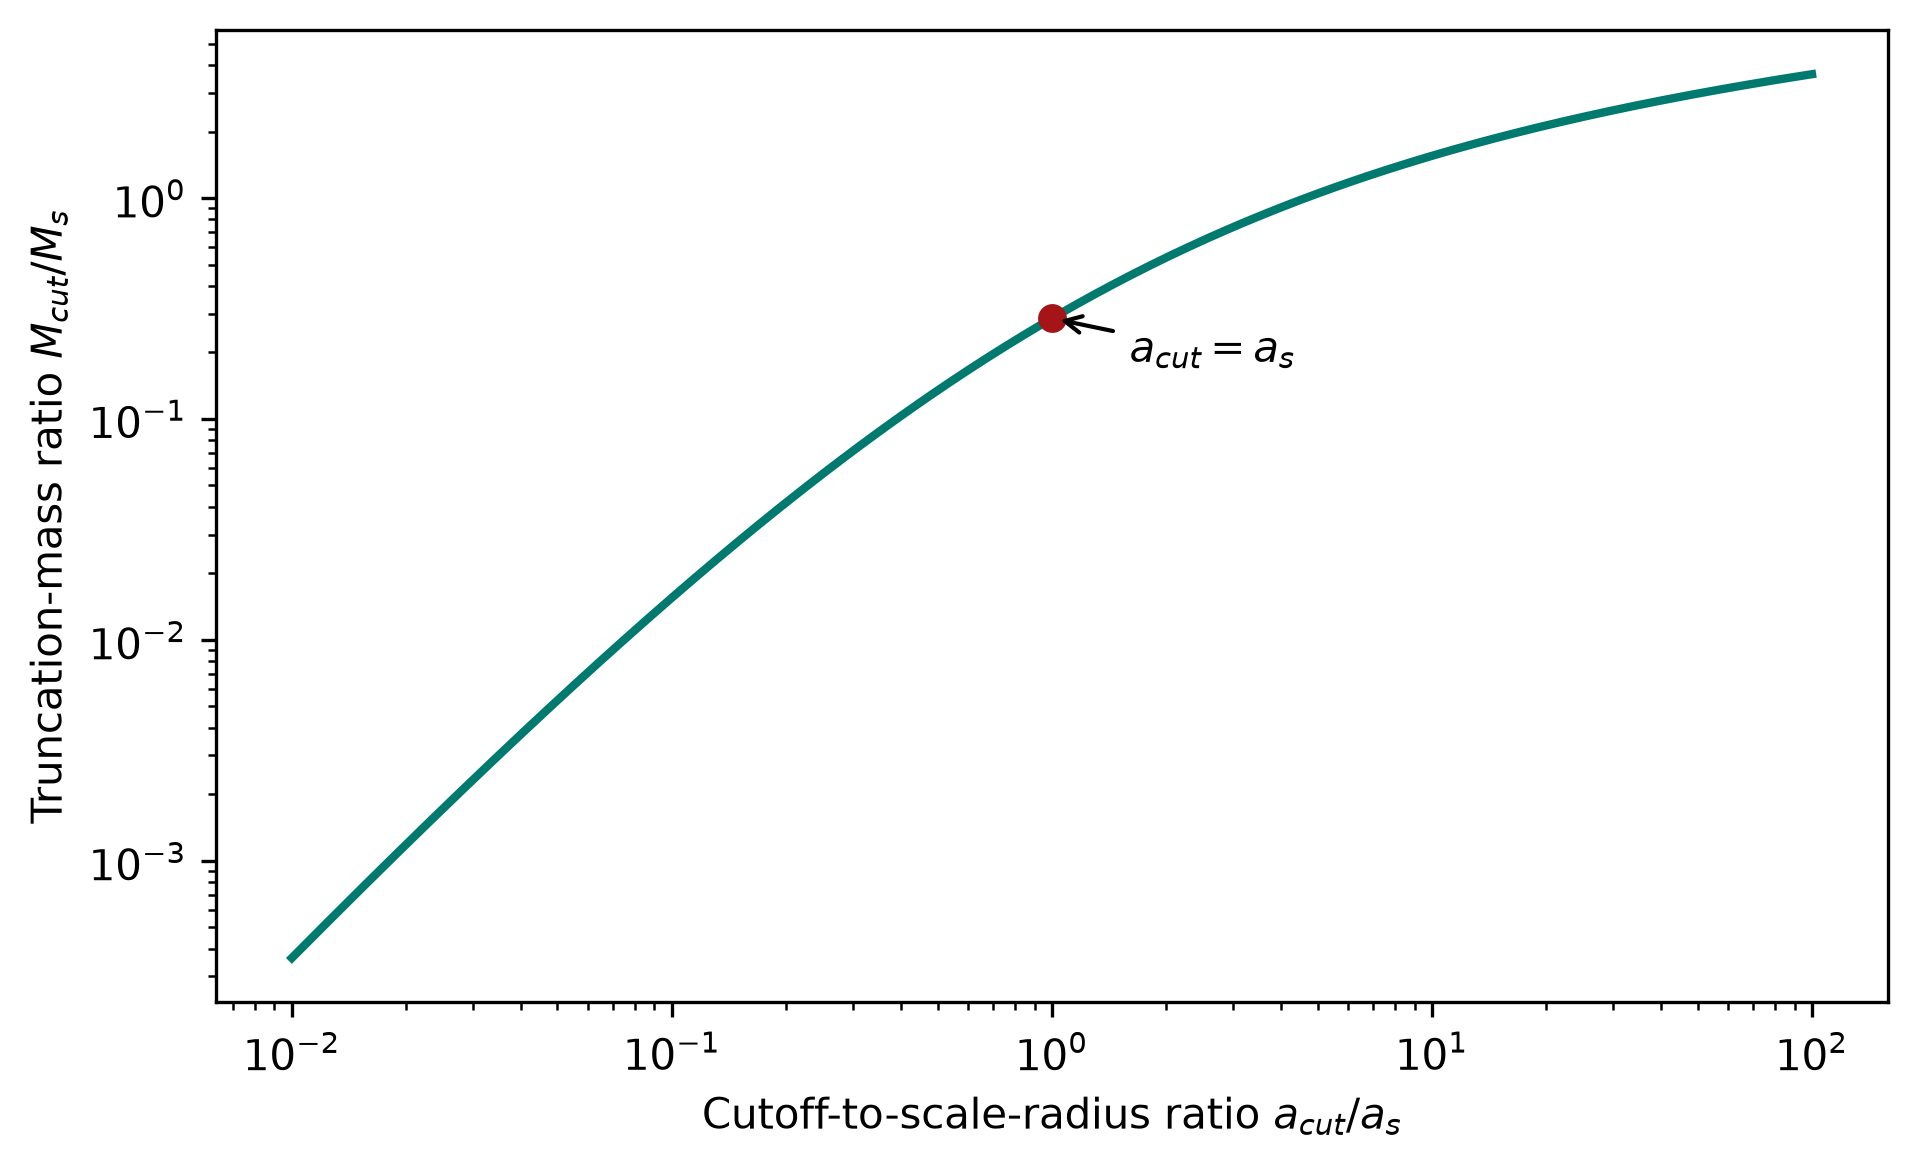

In [1]:
import os
from pathlib import Path
import sys

from IPython.display import Image, display

repository_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if path.name == "chalcedon" and (path / "pyproject.toml").is_file()
)
examples_directory = repository_root / "examples"
if str(examples_directory) not in sys.path:
    sys.path.insert(0, str(examples_directory))

from plot_truncation_mass import run_example

visuals_directory = examples_directory / "visuals"
visuals_directory.mkdir(parents=True, exist_ok=True)
output_path = Path(os.path.relpath(visuals_directory / "truncation_mass.png", Path.cwd()))
radius_ratio, mass_ratio = run_example(output_path)
display(Image(filename=str(output_path)))

## Evaluate a Few Ratios

At a cutoff radius equal to the scale radius, the dimensionless mass ratio is $\pi/4 - 1/2$. The table samples either side of that point using the same Chalcedon kernel.

In [2]:
import numpy as np
import pandas as pd
from chalcedon import retr_mcutfrommscl

sampled_radius_ratios = np.array([0.1, 1.0, 10.0])
sampled_mass_ratios = retr_mcutfrommscl(sampled_radius_ratios)
ratio_table = pd.DataFrame({
    "cutoff_to_scale_radius": sampled_radius_ratios,
    "truncated_mass_ratio": sampled_mass_ratios,
})
display(ratio_table)

,cutoff_to_scale_radius,truncated_mass_ratio
0,0.1,0.015525
1,1.0,0.285398
2,10.0,1.552513
